# Projektive Messung und Born-Regel

Das Notebook erklärt die Born-Regel und die Lüders-Regel aus dem Spektralsatz und simuliert projektive Messungen mit numpy: Häufigkeiten gegen die Anzahl der Messungen, ihre Streuung, Messrichtungen auf der Bloch-Kugel, den Zustand nach der Messung und entartete Eigenwerte an einem Qutrit.

Warum liefert die Messung einer Observablen $A$ im Zustand $\rho$ das Ergebnis $a_k$ mit der Wahrscheinlichkeit $\mathrm{Tr}(\rho P_k)$, und wie schnell nähern sich gemessene Häufigkeiten diesen Werten?

#### **Hintergrund**

Die Quantenmechanik sagt für ein einzelnes Messergebnis nur Wahrscheinlichkeiten voraus. Max Born schlug 1926 vor, das Betragsquadrat der Wellenfunktion als Wahrscheinlichkeit zu lesen; dafür bekam er 1954 den Nobelpreis. In der heutigen Form steht die Regel neben dem Spektralsatz: Eine Observable ist eine selbstadjungierte Matrix, ihre Eigenwerte sind die möglichen Messwerte, und die Projektoren auf die Eigenräume bestimmen, mit welcher Wahrscheinlichkeit welcher Wert kommt und in welchem Zustand das System danach ist (Lüders 1951).

Gebraucht wird das überall, wo man einen Quantenzustand ausliest: beim Auslesen eines Qubits am Ende jeder Quantenschaltung, in der Tomographie, bei Bell-Messungen und in jeder Schätzung aus Messdaten. Weil jede einzelne Messung nur ein Ergebnis liefert, braucht man viele Wiederholungen (Shots); wie viele, sagt die Statistik der Häufigkeiten, die hier simuliert wird.

Landkarte:

- **Spektralsatz**
  - Eine Matrix in Eigenwerte und Projektoren zerlegen (Exp. 1): $A = \sum_k a_kP_k$, die Projektoren summieren sich zur Eins, ein entarteter Eigenwert hat einen Projektor höheren Rangs.
- **Statistik der Messergebnisse**
  - Häufigkeit gegen Anzahl der Messungen (Exp. 2): Die Häufigkeit nähert sich $p(k)$ wie $1/\sqrt N$.
  - Verteilung der Häufigkeit bei festem $N$ (Exp. 3): binomial, für große $N$ fast normalverteilt mit Breite $\sqrt{p(1-p)/N}$.
- **Geometrie**
  - Messrichtung auf der Bloch-Kugel (Exp. 4): $p(\pm) = \tfrac12(1\pm\vec n\cdot\vec r)$.
- **Zustand nach der Messung**
  - Wiederholte und abwechselnde Messungen (Exp. 5): dieselbe Messung zweimal liefert dasselbe Ergebnis, eine dazwischen geschaltete inkompatible Messung löscht die Information.
  - Entartete Eigenwerte (Exp. 6): Eine gröbere Messung lässt Kohärenz innerhalb eines Eigenraums stehen.

Verwandte Notebooks: allgemeine Messungen (POVM, Naimark, schwache Messung, Tomographie) in [Quantenmessung](https://github.com/deltorobarba/science/blob/main/quantum/quantummeasurement.ipynb), Abstandsmaße und Entropien in [Quanteninformation](https://github.com/deltorobarba/science/blob/main/quantum/quantuminformation.ipynb), der Spektralsatz für Matrizen in [Eigenwerte](https://github.com/deltorobarba/science/blob/main/maths/eigenvalues.ipynb).

#### **Theorie**

##### *1. Spektralsatz*

In endlicher Dimension zerfällt eine selbstadjungierte Matrix $A$ in ihre verschiedenen Eigenwerte $a_k$ und die **Projektoren** $P_k$ auf die zugehörigen Eigenräume:
$$A = \sum_k a_k P_k,\qquad P_k^2 = P_k = P_k^\dagger,\qquad P_kP_l = \delta_{kl}P_k,\qquad \sum_k P_k = I.$$
Ein Eigenwert ist **entartet**, wenn sein Eigenraum mehr als eine Dimension hat; der Rang von $P_k$ ist diese Dimension.

##### *2. Born-Regel, Erwartungswert und Varianz*

Die Messung von $A$ im Zustand $\rho$ (einer **Dichtematrix**: positiv semidefinit, Spur 1) liefert $a_k$ mit der Wahrscheinlichkeit
$$p(k) = \mathrm{Tr}(\rho P_k),\qquad\text{für reine Zustände } p(k) = \langle\psi\vert P_k\vert\psi\rangle = \Vert P_k\psi\Vert^2 .$$
Das sind echte Wahrscheinlichkeiten: Wegen $P_k = P_k^\dagger P_k$ ist $p(k) = \mathrm{Tr}(P_k\rho P_k^\dagger)\geq0$, und $\sum_kp(k) = \mathrm{Tr}(\rho\sum_kP_k) = \mathrm{Tr}\,\rho = 1$. Weil die Spur linear ist, folgt der **Erwartungswert** $\langle A\rangle = \sum_k a_k\,p(k) = \mathrm{Tr}(\rho A)$ und die **Varianz** $\mathrm{Var}(A) = \mathrm{Tr}(\rho A^2) - \mathrm{Tr}(\rho A)^2$.

##### *3. Zustand nach der Messung (Lüders-Regel)*

Nach dem Ergebnis $a_k$ ist der Zustand $\rho\mapsto P_k\rho P_k/p(k)$. Misst man dieselbe Observable gleich noch einmal, kommt sicher wieder $a_k$: $\mathrm{Tr}(P_k\rho P_kP_l)/p(k) = \delta_{kl}$, weil $P_kP_l = 0$ für $k\neq l$ und $P_kP_kP_k = P_k$ (**Wiederholbarkeit**). Liest man das Ergebnis nicht, ist der Zustand danach $\sum_kP_k\rho P_k$: Alle Matrixelemente zwischen verschiedenen Eigenräumen werden null, die innerhalb eines Eigenraums bleiben stehen.

##### *4. Qubit und Bloch-Kugel*

Jeder Qubit-Zustand ist $\rho = \tfrac12(I + \vec r\cdot\vec\sigma)$ mit dem **Bloch-Vektor** $\vec r$, $\vert\vec r\vert\leq1$ (gleich 1 für reine Zustände). Für einen Einheitsvektor $\vec n$ gilt $(\vec n\cdot\vec\sigma)^2 = I$, die Eigenwerte sind $\pm1$, und $P_\pm = \tfrac12(I\pm\vec n\cdot\vec\sigma)$ sind die Spektralprojektoren. Mit $\mathrm{Tr}\,\sigma_i = 0$ und $\mathrm{Tr}(\sigma_i\sigma_j) = 2\delta_{ij}$ folgt
$$p(\pm) = \mathrm{Tr}(\rho P_\pm) = \tfrac12(1\pm\vec n\cdot\vec r).$$

##### *5. Statistik der Häufigkeiten*

Bei $N$ unabhängigen Messungen ist die Anzahl $n_k$ der Ergebnisse $a_k$ **binomialverteilt**. Jede Messung ist ein Bernoulli-Versuch $X_i\in\{0, 1\}$ mit $\mathbb EX_i = p$ und $\mathrm{Var}\,X_i = p(1-p)$; die Varianzen unabhängiger Versuche addieren sich. Die Häufigkeit $f_k = n_k/N$ hat daher den Erwartungswert $p(k)$ und die **Standardabweichung** $\sqrt{p(k)(1-p(k))/N}$; sie ist bei $p = \tfrac12$ am größten, $1/(2\sqrt N)$. Für große $N$ ist $f_k$ nach dem zentralen Grenzwertsatz fast normalverteilt.

#### **Code**

Werkzeuge: Pauli-Matrizen, Spektralzerlegung, Born-Wahrscheinlichkeiten und simulierte Messungen.

In [1]:
import numpy as np
import matplotlib.pyplot as plt

rng = np.random.default_rng(42)

I2 = np.eye(2, dtype=complex)
sx = np.array([[0, 1], [1, 0]], dtype=complex)
sy = np.array([[0, -1j], [1j, 0]])
sz = np.array([[1, 0], [0, -1]], dtype=complex)


def spektralzerlegung(A, tol=1e-9):
    """Verschiedene Eigenwerte a_k von A und die Projektoren P_k auf ihre Eigenräume."""
    w, V = np.linalg.eigh(A)
    werte = []
    for a in w:                                   # entartete Eigenwerte nur einmal aufnehmen
        if not any(abs(a - b) < tol for b in werte):
            werte.append(a)
    projektoren = []
    for a in werte:
        Vk = V[:, np.abs(w - a) < tol]            # Eigenvektoren zum Eigenwert a
        projektoren.append(Vk @ Vk.conj().T)
    return np.array(werte), projektoren


def born(rho, projektoren):
    """Born-Wahrscheinlichkeiten p(k) = Tr(rho P_k)."""
    return np.array([np.trace(rho @ P).real for P in projektoren])


def messen(rho, A, N):
    """N unabhängige Messungen von A im Zustand rho; gibt die Messwerte zurück."""
    werte, P = spektralzerlegung(A)
    p = born(rho, P)
    return rng.choice(werte, size=N, p=p / p.sum())


def bloch_zustand(theta, phi):
    """Reiner Qubit-Zustand mit den Bloch-Winkeln theta und phi als Dichtematrix."""
    psi = np.array([np.cos(theta / 2), np.exp(1j * phi) * np.sin(theta / 2)])
    return np.outer(psi, psi.conj())

#### **Experimente**

##### *1. Kontrolle des Spektralsatzes*

Zerfällt eine Matrix mit einem entarteten Eigenwert so in Projektoren, wie Abschnitt 1 der Theorie sagt? Die Matrix unten hat die Eigenwerte 1 und 3, wobei 3 zweifach entartet ist. Vorher überlegen: Welchen Rang haben die beiden Projektoren?

Die Funktion `spektralzerlegung` sammelt die verschiedenen Eigenwerte und baut für jeden den Projektor aus seinen Eigenvektoren. Geprüft werden die Zerlegung $A = \sum_ka_kP_k$, die Vollständigkeit $\sum_kP_k = I$ und die Orthogonalität $P_kP_l = 0$.

**Hintergrund & Fachbegriffe:**
- **Selbstadjungiert (hermitesch):** $A = A^\dagger$; solche Matrizen haben reelle Eigenwerte und eine Orthonormalbasis aus Eigenvektoren. Observablen sind selbstadjungiert, weil Messwerte reell sind.
- **Projektor:** eine Matrix mit $P^2 = P = P^\dagger$; sie bildet auf einen Unterraum ab und lässt Vektoren darin unverändert. Ihre Spur ist der Rang, also die Dimension des Unterraums.
- **Entarteter Eigenwert:** ein Eigenwert mit mehreren linear unabhängigen Eigenvektoren; sein Projektor hat Rang größer als 1.

In [2]:
A = np.array([[2, 1, 0], [1, 2, 0], [0, 0, 3]], dtype=complex)
werte, P = spektralzerlegung(A)
print("Eigenwerte:        ", np.round(werte, 6))
print("A = Σ a_k P_k:     ", np.allclose(A, sum(a * Pk for a, Pk in zip(werte, P))))
print("Σ P_k = I:         ", np.allclose(sum(P), np.eye(3)))
print("P_k P_l = 0 (k≠l): ", all(np.allclose(P[i] @ P[j], 0) for i in range(len(P)) for j in range(len(P)) if i != j))
print("Rang der P_k:      ", [int(round(np.trace(Pk).real)) for Pk in P])

Eigenwerte:         [1. 3.]
A = Σ a_k P_k:      True
Σ P_k = I:          True
P_k P_l = 0 (k≠l):  True
Rang der P_k:       [1, 2]


* Die **Eigenwerte** sind 1 und 3. Die Funktion nimmt den zweifachen Eigenwert 3 nur einmal auf und baut für ihn einen Projektor aus beiden Eigenvektoren.
* Alle drei Prüfungen liefern `True`: $A$ ist gleich $1\cdot P_1 + 3\cdot P_3$, die beiden Projektoren summieren sich zur Einheitsmatrix und stehen senkrecht aufeinander.
* Die **Ränge** sind 1 und 2: Der Projektor zum entarteten Eigenwert 3 projiziert auf eine Ebene. Genau diese Entartung spielt in Experiment 6 die Hauptrolle.

##### *2. Häufigkeit gegen Anzahl der Messungen*

Wie schnell nähert sich die gemessene Häufigkeit von $+1$ der Born-Wahrscheinlichkeit, und liegt die Streuung im Band $\pm\sqrt{p(1-p)/N}$? Erst vorhersagen: Wie groß ist $p(+1)$ für den Bloch-Winkel $\theta = 120°$?

Ein reiner Qubit-Zustand mit den Bloch-Winkeln $\theta = 2\pi/3$ und $\phi = 0{,}4$ wird 10 000-mal in $\sigma_z$ gemessen. Nach jeder Messung wird die laufende Häufigkeit des Ergebnisses $+1$ berechnet und mit der Born-Wahrscheinlichkeit $p(+1) = \cos^2(\theta/2)$ und dem Band einer Standardabweichung verglichen (Theorie, Abschnitt 5).

**Hintergrund & Fachbegriffe:**
- **$\sigma_z$-Messung:** die Messung in der Rechenbasis $\vert0\rangle, \vert1\rangle$ mit den Ergebnissen $+1$ und $-1$; so liest ein Quantencomputer ein Qubit aus.
- **Bloch-Winkel:** $\vert\psi\rangle = \cos(\theta/2)\vert0\rangle + e^{i\phi}\sin(\theta/2)\vert1\rangle$; $\theta$ ist der Winkel zum Nordpol der Bloch-Kugel, $\phi$ der Winkel um die $z$-Achse.
- **Laufende Häufigkeit:** der Anteil der Ergebnisse $+1$ unter den ersten $N$ Messungen; aufeinanderfolgende Werte hängen zusammen, weil sie dieselben frühen Messungen enthalten.
- **Gesetz der großen Zahlen:** Die Häufigkeit strebt gegen die Wahrscheinlichkeit; die Abweichung schrumpft typischerweise wie $1/\sqrt N$.

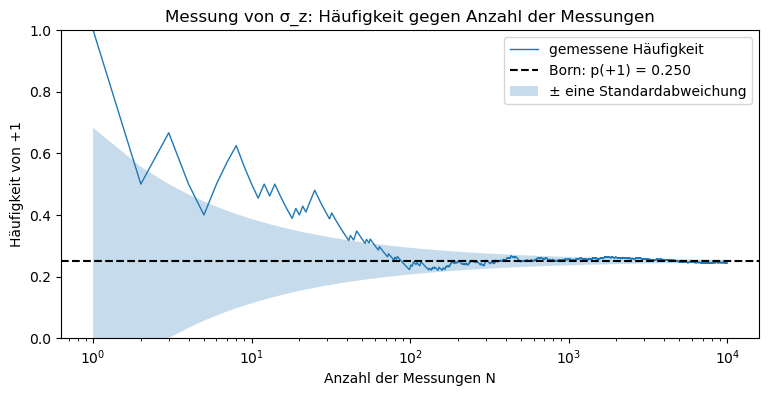

p(+1) = 0.2500; nach N = 10000: Häufigkeit 0.2442, Abweichung 0.0058, eine Standardabweichung 0.0043
Anteil der N, bei denen die laufende Häufigkeit im Band ±σ liegt: 0.65


In [3]:
theta, phi = 2 * np.pi / 3, 0.4
rho = bloch_zustand(theta, phi)
p_plus = np.trace(rho @ (I2 + sz) / 2).real          # Born-Wahrscheinlichkeit für +1

N_max = 10_000
ergebnisse = messen(rho, sz, N_max)
N = np.arange(1, N_max + 1)
f_plus = np.cumsum(np.isclose(ergebnisse, 1)) / N     # laufende Häufigkeit von +1
sigma = np.sqrt(p_plus * (1 - p_plus) / N)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(N, f_plus, lw=1, label="gemessene Häufigkeit")
ax.axhline(p_plus, color="k", ls="--", label=f"Born: p(+1) = {p_plus:.3f}")
ax.fill_between(N, p_plus - sigma, p_plus + sigma, alpha=0.25, label="± eine Standardabweichung")
ax.set_xscale("log")
ax.set_ylim(0, 1)
ax.set_xlabel("Anzahl der Messungen N")
ax.set_ylabel("Häufigkeit von +1")
ax.set_title("Messung von σ_z: Häufigkeit gegen Anzahl der Messungen")
ax.legend()
plt.show()
print(f"p(+1) = {p_plus:.4f}; nach N = {N_max}: Häufigkeit {f_plus[-1]:.4f}, Abweichung {abs(f_plus[-1] - p_plus):.4f}, "
      f"eine Standardabweichung {sigma[-1]:.4f}")
print(f"Anteil der N, bei denen die laufende Häufigkeit im Band ±σ liegt: {np.mean(np.abs(f_plus - p_plus) <= sigma):.2f}")

* Das Bild zeigt die laufende Häufigkeit von $+1$ (blaue Linie) gegen die Anzahl $N$ der Messungen, mit logarithmischer $x$-Achse. Die gestrichelte Linie ist die Born-Wahrscheinlichkeit $p(+1) = \cos^2(60°) = 0{,}25$, das hellblaue Band reicht eine Standardabweichung $\sqrt{p(1-p)/N}$ darüber und darunter.
* Am Anfang springt die Häufigkeit stark: Die erste Messung ergab zufällig $+1$, also Häufigkeit 1, und bis etwa $N = 60$ liegt die Linie über dem Band. Ab einigen hundert Messungen bleibt sie im Band, das sich wie $1/\sqrt N$ zusammenzieht.
* Die **Ausgabe** nennt nach 10 000 Messungen die Häufigkeit 0,2442, also 0,0058 neben 0,25; eine Standardabweichung ist dort 0,0043, die Abweichung ist also 1,4 Standardabweichungen. Die laufende Häufigkeit liegt bei 65 % aller $N$ im Band, nahe an den 68 %, die eine Normalverteilung erwarten lässt (die Werte für benachbarte $N$ hängen allerdings zusammen).

##### *3. Verteilung der Häufigkeit bei festem N*

Wiederholt man die Serie von $N = 100$ Messungen 5000-mal, wie verteilt sich die Häufigkeit? Vorher skizzieren: Mittelwert, Breite, Form.

Derselbe Zustand wie in Experiment 2 wird in 5000 unabhängigen Serien zu je 100 Messungen gemessen; jede Serie liefert eine Häufigkeit von $+1$. Das Histogramm dieser Häufigkeiten wird mit der Normalverteilung mit Mittelwert $p(+1)$ und Standardabweichung $\sqrt{p(1-p)/N}$ verglichen.

**Hintergrund & Fachbegriffe:**
- **Binomialverteilung:** die Verteilung der Anzahl von Erfolgen in $N$ unabhängigen Versuchen mit Erfolgswahrscheinlichkeit $p$; Mittelwert $Np$, Varianz $Np(1-p)$.
- **Zentraler Grenzwertsatz:** Summen vieler unabhängiger Zufallsgrößen sind näherungsweise normalverteilt; deshalb passt die Gauß-Kurve schon bei $N = 100$ gut.
- **Shot Noise:** die statistische Streuung, die allein daher kommt, dass man nur endlich viele Messungen macht; sie begrenzt jede Schätzung aus Messdaten.

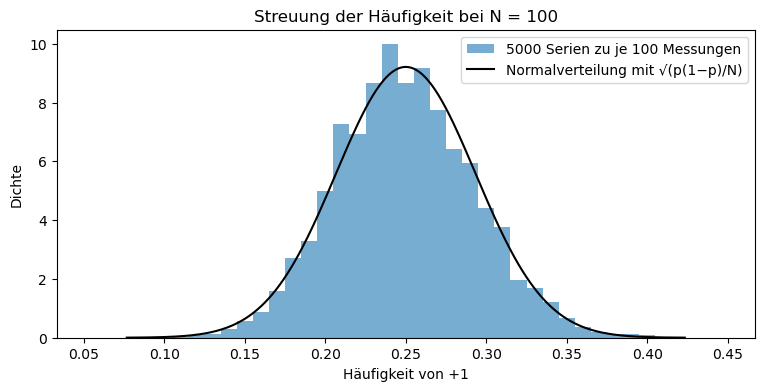

gemessene Standardabweichung 0.0430, vorhergesagt 0.0433


In [4]:
N_fest, wiederholungen = 100, 5000
f = np.array([np.mean(np.isclose(messen(rho, sz, N_fest), 1)) for _ in range(wiederholungen)])

s = np.sqrt(p_plus * (1 - p_plus) / N_fest)
x = np.linspace(p_plus - 4 * s, p_plus + 4 * s, 300)

fig, ax = plt.subplots(figsize=(9, 4))
ax.hist(f, bins=np.arange(-0.005, 1.005, 0.01), density=True, alpha=0.6, label=f"{wiederholungen} Serien zu je {N_fest} Messungen")
ax.plot(x, np.exp(-(x - p_plus) ** 2 / (2 * s**2)) / (s * np.sqrt(2 * np.pi)), "k", label="Normalverteilung mit √(p(1−p)/N)")
ax.set_xlim(p_plus - 5 * s, p_plus + 5 * s)
ax.set_xlabel("Häufigkeit von +1")
ax.set_ylabel("Dichte")
ax.set_title(f"Streuung der Häufigkeit bei N = {N_fest}")
ax.legend()
plt.show()
print(f"gemessene Standardabweichung {f.std():.4f}, vorhergesagt {s:.4f}")

* Das Histogramm zeigt die Häufigkeiten von $+1$ aus 5000 Serien zu je 100 Messungen, die schwarze Kurve die Normalverteilung mit Mittelwert 0,25 und Standardabweichung $\sqrt{0{,}25\cdot0{,}75/100} = 0{,}0433$. Die Balken liegen in Schritten von 0,01, weil bei 100 Messungen nur Häufigkeiten $n/100$ möglich sind.
* Mittelwert, Breite und glockenförmige Form stimmen mit der Kurve überein: Schon bei $N = 100$ ist die Binomialverteilung kaum von der Normalverteilung zu unterscheiden (zentraler Grenzwertsatz).
* Die **Ausgabe** nennt die gemessene Standardabweichung 0,0430 gegen vorhergesagt 0,0433. Eine einzelne Serie von 100 Messungen bestimmt $p(+1)$ also nur auf etwa $\pm0{,}04$ genau; für eine Stelle mehr braucht man 100-mal so viele Messungen.

##### *4. Messrichtung auf der Bloch-Kugel*

Wie hängt $p(+1)$ vom Winkel zwischen Messrichtung $\vec n$ und Bloch-Vektor $\vec r$ ab? Vorher die Kurve aus $p(\pm) = \tfrac12(1\pm\vec n\cdot\vec r)$ skizzieren.

Der Zustand aus Experiment 2 wird in 13 Richtungen $\vec n$ in der $x$-$z$-Ebene gemessen, vom Nordpol ($0°$) bis zum Südpol ($180°$), je 2000-mal. Verglichen wird die gemessene Häufigkeit von $+1$ mit der Born-Regel aus Abschnitt 4 der Theorie.

**Hintergrund & Fachbegriffe:**
- **Bloch-Vektor:** $\vec r = (\langle\sigma_x\rangle, \langle\sigma_y\rangle, \langle\sigma_z\rangle)$; für reine Zustände liegt er auf der Oberfläche der Einheitskugel.
- **Messung von $\vec n\cdot\vec\sigma$:** eine Spin-Messung entlang der Richtung $\vec n$; die Ergebnisse sind immer $\pm1$, nur ihre Wahrscheinlichkeiten hängen von der Richtung ab.
- **Skalarprodukt $\vec n\cdot\vec r$:** der Kosinus des Winkels zwischen Messrichtung und Bloch-Vektor (mal $\vert\vec r\vert$); er bestimmt allein die Wahrscheinlichkeit.

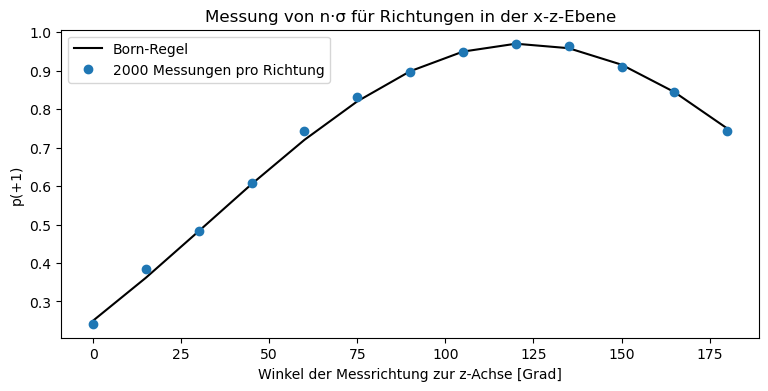

Bloch-Vektor r = [ 0.798  0.337 -0.5  ]; p(+1) von 0.250 bis 0.970
größte Abweichung Messung gegen Born-Regel: 0.024 bei 60°
in Standardabweichungen: größter Wert 2.4 bei 60°, Mittelwert 0.82


In [5]:
r = np.array([np.sin(theta) * np.cos(phi), np.sin(theta) * np.sin(phi), np.cos(theta)])   # Bloch-Vektor von rho

winkel = np.linspace(0, np.pi, 13)                      # Messrichtung in der x-z-Ebene
p_theorie, p_gemessen = [], []
for a in winkel:
    n = np.array([np.sin(a), 0, np.cos(a)])
    A = n[0] * sx + n[1] * sy + n[2] * sz
    p_gemessen.append(np.mean(np.isclose(messen(rho, A, 2000), 1)))
    p_theorie.append((1 + n @ r) / 2)

fig, ax = plt.subplots(figsize=(9, 4))
ax.plot(np.degrees(winkel), p_theorie, "k-", label="Born-Regel")
ax.plot(np.degrees(winkel), p_gemessen, "o", label="2000 Messungen pro Richtung")
ax.set_xlabel("Winkel der Messrichtung zur z-Achse [Grad]")
ax.set_ylabel("p(+1)")
ax.set_title("Messung von n·σ für Richtungen in der x-z-Ebene")
ax.legend()
plt.show()
abw = np.abs(np.array(p_gemessen) - np.array(p_theorie))
print(f"Bloch-Vektor r = {np.round(r, 3)}; p(+1) von {min(p_theorie):.3f} bis {max(p_theorie):.3f}")
sig = np.sqrt(np.array(p_theorie) * (1 - np.array(p_theorie)) / 2000)   # Standardabweichung je Richtung
z = abw / sig
print(f"größte Abweichung Messung gegen Born-Regel: {abw.max():.3f} bei {np.degrees(winkel[abw.argmax()]):.0f}°")
print(f"in Standardabweichungen: größter Wert {z.max():.1f} bei {np.degrees(winkel[z.argmax()]):.0f}°, Mittelwert {z.mean():.2f}")

* Das Bild zeigt $p(+1)$ gegen den Winkel der Messrichtung zur $z$-Achse in der $x$-$z$-Ebene: die Born-Regel $\tfrac12(1 + \vec n\cdot\vec r)$ (schwarze Linie) und die Häufigkeiten aus je 2000 Messungen (Punkte). Die Kurve ist eine verschobene Kosinuskurve mit dem Maximum bei 120°, wo $\vec n$ der Projektion des Bloch-Vektors in die Ebene am nächsten kommt.
* Das Maximum ist 0,970 und nicht 1: Der Bloch-Vektor $\vec r = (0{,}798;\ 0{,}337;\ -0{,}5)$ zeigt mit seiner $y$-Komponente aus der Messebene heraus, deshalb ist $\vec n\cdot\vec r$ höchstens $\sqrt{0{,}798^2 + 0{,}5^2} = 0{,}942$. Am Nordpol ($0°$) ist $p(+1) = 0{,}25$ wie in Experiment 2, am Südpol 0,75.
* Die **Ausgabe** nennt die größte Abweichung 0,024 bei 60°, das sind 2,4 Standardabweichungen; im Mittel liegen die Punkte 0,82 Standardabweichungen neben der Linie, nahe am Erwartungswert 0,80 für normalverteiltes Rauschen. Bei 13 Richtungen ist ein Ausreißer dieser Größe in etwa jedem fünften Lauf zu erwarten.

##### *5. Zustand nach der Messung*

Was sagt die Lüders-Regel für zwei Folgen voraus: (a) $\sigma_z$, dann $\sigma_z$; (b) $\sigma_z$, dann $\sigma_x$, dann $\sigma_z$? Vorhersage aufschreiben: In wie vielen von 1000 Fällen stimmen erstes und letztes Ergebnis überein?

Jede Messung wählt ein Ergebnis nach der Born-Regel und ersetzt den Zustand durch $P_k\rho P_k/p(k)$ (Theorie, Abschnitt 3). Beide Folgen werden 1000-mal durchgespielt, und gezählt wird, wie oft das erste und das letzte $\sigma_z$-Ergebnis gleich sind.

**Hintergrund & Fachbegriffe:**
- **Kollaps:** die Ersetzung des Zustands durch den normierten projizierten Zustand nach einem gelesenen Ergebnis.
- **Inkompatible Observablen:** Observablen, deren Projektoren nicht vertauschen, wie $\sigma_z$ und $\sigma_x$; eine Messung der einen zerstört die Information über die andere.
- **Quanten-Zeno-Effekt (Ausblick):** Sehr häufiges Messen derselben Observablen friert den Zustand ein, weil jede Messung ihn in den Eigenraum zurückwirft.

In [6]:
def messen_mit_kollaps(rho, A):
    """Eine Messung: Ergebnis a_k und Zustand P_k rho P_k / p(k) danach."""
    werte, P = spektralzerlegung(A)
    p = born(rho, P)
    k = rng.choice(len(werte), p=p / p.sum())
    return werte[k], P[k] @ rho @ P[k] / p[k]


gleich_a = gleich_b = 0
for _ in range(1000):
    a1, rho1 = messen_mit_kollaps(rho, sz)
    a2, _ = messen_mit_kollaps(rho1, sz)
    gleich_a += np.isclose(a1, a2)

    b1, rho1 = messen_mit_kollaps(rho, sz)
    _, rho2 = messen_mit_kollaps(rho1, sx)
    b3, _ = messen_mit_kollaps(rho2, sz)
    gleich_b += np.isclose(b1, b3)

print("(a) σ_z, dann σ_z:          gleiches Ergebnis in", gleich_a, "von 1000 Fällen")
print("(b) σ_z, dann σ_x, dann σ_z: gleiches Ergebnis in", gleich_b, "von 1000 Fällen")

(a) σ_z, dann σ_z:          gleiches Ergebnis in 1000 von 1000 Fällen
(b) σ_z, dann σ_x, dann σ_z: gleiches Ergebnis in 495 von 1000 Fällen


* **Folge (a):** In allen 1000 Fällen liefert die zweite $\sigma_z$-Messung dasselbe Ergebnis wie die erste. Das ist die Wiederholbarkeit aus Abschnitt 3 der Theorie: Nach dem Ergebnis $+1$ ist der Zustand $\vert0\rangle$, und dort kommt $+1$ mit Sicherheit.
* **Folge (b):** Nur in 495 von 1000 Fällen stimmen erstes und letztes Ergebnis überein, also in etwa der Hälfte. Die $\sigma_x$-Messung dazwischen setzt den Zustand auf $\vert+\rangle$ oder $\vert-\rangle$, und in beiden ist $p(\pm1) = \tfrac12$ für $\sigma_z$: Die Information aus der ersten Messung ist gelöscht.
* Die Abweichung von 500 ist 5 Fälle; die Standardabweichung bei 1000 Versuchen mit $p = \tfrac12$ ist $\sqrt{1000\cdot0{,}25}\approx16$ Fälle.

##### *6. Entartete Eigenwerte*

Ein Qutrit im Zustand $(\vert0\rangle + \vert1\rangle + \vert2\rangle)/\sqrt3$ wird einmal mit $A = \mathrm{diag}(1, 1, -1)$ gemessen und einmal mit der feineren Observablen $B = \mathrm{diag}(1, 2, -1)$. Was bleibt von der Kohärenz zwischen $\vert0\rangle$ und $\vert1\rangle$ übrig, wenn man das Ergebnis nicht liest? Vorher begründen, warum sich $A$ und $B$ unterscheiden.

Für beide Observablen wird der Zustand nach der Messung ohne gelesenes Ergebnis berechnet, $\sum_kP_k\rho P_k$, und das Matrixelement $\langle0\vert\rho\vert1\rangle$ vorher und nachher verglichen.

**Hintergrund & Fachbegriffe:**
- **Qutrit:** ein Quantensystem mit drei Basiszuständen $\vert0\rangle, \vert1\rangle, \vert2\rangle$.
- **Kohärenz:** ein Nichtdiagonalelement der Dichtematrix wie $\langle0\vert\rho\vert1\rangle$; es misst die Fähigkeit zur Interferenz zwischen den beiden Basiszuständen.
- **Gröbere und feinere Messung:** $A$ unterscheidet $\vert0\rangle$ und $\vert1\rangle$ nicht (gleicher Eigenwert 1), $B$ schon; eine Messung zerstört nur die Kohärenz zwischen Zuständen, die sie unterscheidet.

In [7]:
psi = np.ones(3) / np.sqrt(3)
rho3 = np.outer(psi, psi.conj())

for name, obs in [("A = diag(1, 1, -1), entartet  ", np.diag([1, 1, -1]).astype(complex)),
                  ("B = diag(1, 2, -1), verfeinert", np.diag([1, 2, -1]).astype(complex))]:
    werte, P = spektralzerlegung(obs)
    rho_nach = sum(Pk @ rho3 @ Pk for Pk in P)          # Zustand nach der Messung, Ergebnis nicht gelesen
    print(f"{name}: Element <0|rho|1> vorher {rho3[0, 1].real:.3f}, nachher {rho_nach[0, 1].real:.3f}")

A = diag(1, 1, -1), entartet  : Element <0|rho|1> vorher 0.333, nachher 0.333
B = diag(1, 2, -1), verfeinert: Element <0|rho|1> vorher 0.333, nachher 0.000


* Mit der **entarteten Observablen** $A$ bleibt das Element $\langle0\vert\rho\vert1\rangle = 0{,}333$ unverändert: $\vert0\rangle$ und $\vert1\rangle$ liegen im selben Eigenraum zum Eigenwert 1, und $A$ kann sie nicht unterscheiden. Gelöscht werden nur die Kohärenzen zu $\vert2\rangle$.
* Mit der **feineren Observablen** $B$ ist das Element danach 0: $B$ unterscheidet $\vert0\rangle$ und $\vert1\rangle$ (Eigenwerte 1 und 2), und die Messung zerstört die Kohärenz zwischen ihnen, auch wenn niemand das Ergebnis liest.
* Merksatz: Eine Messung zerstört genau die Kohärenzen zwischen Zuständen, die sie unterscheidet. Das ist der Unterschied zwischen der Lüders-Regel (Projektion auf den ganzen Eigenraum) und einer Messung in einer vollständigen Basis.

#### **Ergebnis**

Beim Lauf vom 2026-10-31 (Zufallsgenerator mit Seed 42):

- **Spektralsatz:** Die Matrix mit den Eigenwerten 1 und 3 (zweifach) zerfällt in zwei orthogonale Projektoren vom Rang 1 und 2, die sich zur Einheitsmatrix summieren.
- **Häufigkeit gegen N:** Für $p(+1) = 0{,}25$ liefert die laufende Häufigkeit nach 10 000 Messungen 0,2442, 1,4 Standardabweichungen neben dem Born-Wert; bei 65 % aller $N$ liegt sie im Band $\pm\sqrt{p(1-p)/N}$.
- **Verteilung bei N = 100:** Über 5000 Serien ist die Standardabweichung der Häufigkeit 0,0430, vorhergesagt 0,0433; die Verteilung ist schon fast normal.
- **Bloch-Kugel:** Die Häufigkeiten in 13 Richtungen folgen $\tfrac12(1 + \vec n\cdot\vec r)$; das Maximum 0,970 liegt bei 120°, kleiner als 1, weil der Bloch-Vektor aus der Messebene zeigt. Größte Abweichung 2,4 Standardabweichungen, im Mittel 0,82.
- **Lüders-Regel:** $\sigma_z$ zweimal: 1000 von 1000 gleiche Ergebnisse; mit $\sigma_x$ dazwischen: 495 von 1000.
- **Entartung:** Die gröbere Messung $A$ lässt $\langle0\vert\rho\vert1\rangle = 0{,}333$ stehen, die feinere $B$ setzt es auf 0.

#### **Variationen**

Jeweils zuerst die Vorhersage aufschreiben, dann den Code ändern.

1. Ersetze $\rho$ durch den gemischten Zustand $(1-\lambda)\rho + \lambda I/2$. Wie ändert sich die Kurve in Experiment 3?
2. Wähle $\theta$ so, dass $p(+1) = 1/2$. Wird das Band in Experiment 1 breiter oder schmaler?
3. Wie viele Messungen braucht man, damit die Häufigkeit mit 95 % Wahrscheinlichkeit auf 0,01 genau ist? Erst mit der Hoeffding-Ungleichung $P(\vert f - p\vert\geq\epsilon)\leq2e^{-2N\epsilon^2}$ rechnen, dann simulieren.
4. Ersetze in Experiment 4 (b) $\sigma_x$ durch $(\sigma_x + \sigma_z)/\sqrt2$. Wie oft stimmen erstes und letztes Ergebnis jetzt überein?

#### **Wiederholung**

Erst selbst antworten, dann aufklappen.

<details><summary>1. Was sagt der Spektralsatz für eine selbstadjungierte Matrix?</summary>

Sie ist die Summe ihrer verschiedenen Eigenwerte mal die Projektoren auf die Eigenräume, $A = \sum_ka_kP_k$; die Projektoren sind orthogonal und summieren sich zur Einheitsmatrix.
</details>

<details><summary>2. Wie lautet die Born-Regel für eine Dichtematrix, und warum sind die Werte Wahrscheinlichkeiten?</summary>

$p(k) = \mathrm{Tr}(\rho P_k)$. Sie sind nichtnegativ, weil $P_k\rho P_k$ positiv semidefinit ist, und summieren sich zu 1, weil $\sum_kP_k = I$ und $\mathrm{Tr}\,\rho = 1$.
</details>

<details><summary>3. Wie folgt der Erwartungswert Tr(ρA) aus der Born-Regel?</summary>

$\sum_ka_kp(k) = \sum_ka_k\mathrm{Tr}(\rho P_k) = \mathrm{Tr}(\rho\sum_ka_kP_k) = \mathrm{Tr}(\rho A)$, weil die Spur linear ist.
</details>

<details><summary>4. Was ist der Zustand nach dem Ergebnis a_k, und was passiert bei einer zweiten Messung derselben Observablen?</summary>

$P_k\rho P_k/p(k)$ (Lüders-Regel). Die zweite Messung liefert mit Sicherheit wieder $a_k$, weil $P_kP_l = 0$ für $l\neq k$.
</details>

<details><summary>5. Mit welcher Wahrscheinlichkeit liefert die Messung von n·σ das Ergebnis +1?</summary>

$p(+) = \tfrac12(1 + \vec n\cdot\vec r)$: 1, wenn die Messrichtung parallel zum Bloch-Vektor eines reinen Zustands ist, 0 bei antiparallel, $\tfrac12$ senkrecht dazu.
</details>

<details><summary>6. Wie groß ist die Standardabweichung der Häufigkeit bei N Messungen, und wann ist sie am größten?</summary>

$\sqrt{p(1-p)/N}$; am größten bei $p = \tfrac12$, dort $1/(2\sqrt N)$.
</details>

<details><summary>7. Wie viele Messungen braucht man ungefähr für eine Genauigkeit von 0,01 bei p = 1/2?</summary>

Eine Standardabweichung $1/(2\sqrt N) = 0{,}01$ ergibt $N = 2500$; für etwa 95 % Sicherheit (zwei Standardabweichungen) rund 10 000.
</details>

<details><summary>8. Warum stimmen in Folge (b) von Experiment 5 erstes und letztes Ergebnis nur in etwa der Hälfte der Fälle überein?</summary>

Nach der $\sigma_x$-Messung ist der Zustand ein Eigenzustand von $\sigma_x$, also $\vert\pm\rangle$, in dem beide $\sigma_z$-Ergebnisse die Wahrscheinlichkeit $\tfrac12$ haben. Die Information aus der ersten Messung ist gelöscht.
</details>

<details><summary>9. Warum lässt die Messung von A = diag(1, 1, −1) die Kohärenz zwischen |0⟩ und |1⟩ stehen?</summary>

Beide liegen im selben Eigenraum zum Eigenwert 1; der Projektor auf diesen Eigenraum ändert nichts an Matrixelementen innerhalb des Raums. Nur Kohärenzen zwischen verschiedenen Eigenräumen werden gelöscht.
</details>

<details><summary>10. Was ist der Unterschied zwischen einer Messung mit gelesenem und einer mit nicht gelesenem Ergebnis?</summary>

Mit gelesenem Ergebnis ist der Zustand $P_k\rho P_k/p(k)$ (ein Zweig). Ohne gelesenes Ergebnis ist er die Mischung aller Zweige, $\sum_kP_k\rho P_k$: Die Diagonale bleibt, die Kohärenzen zwischen Eigenräumen verschwinden.
</details>

#### **Nächste Schritte**

- **Allgemeine Messungen:** Nicht jede Messung ist projektiv. POVMs, ihre Umsetzung mit einem Hilfssystem (Naimark), schwache Messungen und Tomographie stehen in [Quantenmessung](https://github.com/deltorobarba/science/blob/main/quantum/quantummeasurement.ipynb).
- **Wie gut lassen sich Zustände unterscheiden:** Spurabstand, Fidelity und Helstrom-Grenze in [Quanteninformation](https://github.com/deltorobarba/science/blob/main/quantum/quantuminformation.ipynb).
- **Echte Hardware:** dieselbe $\sigma_z$-Messung auf einem IBM-Quantencomputer, mit Rauschen, in [Bell-Zustand präparieren](https://github.com/deltorobarba/science/blob/main/quantum/bellstatepreparation.ipynb).
- **Genauere Schranken:** Statt der Normalnäherung die Hoeffding- und die Chernoff-Schranke für die Zahl der nötigen Messungen herleiten (Variation 3).

#### **Referenzen**

- M. A. Nielsen, I. L. Chuang: *Quantum Computation and Quantum Information*, Abschnitte 2.2.3 (Quantenmessung) und 2.2.5 (projektive Messungen).
- G. Teschl: *Mathematical Methods in Quantum Mechanics*, Kapitel 3 (Spektralsatz).